In [1]:
import sys
sys.path.insert(1, '/home/santolam/MyPythonLibrary/MAR_HMA_evaluation_paper/libmar/')
import climbasis as climb
from climbasis import *
import domain as dom
import myplot
import numpy.ma as ma
from myplot import *


In [2]:
#!ls /home/santolam/NST*

In [3]:
dsHMA=xr.open_dataset('/home/santolam/NST.2000.09.01.00.GRh.nc')
dsSH_hma=dsHMA['SH']#[nx:-nx,ny:-ny]
LONS_hma,LATS_hma=dsHMA.LON,dsHMA.LAT

In [4]:
nx=ny=10
ds_nepal=xr.open_dataset('/home/santolam/NST.2000.01.01.00.GRc.nc')#['SH']#[nx:-nx,ny:-ny]
dsSH_nepal=ds_nepal['SH'][nx:-nx,ny:-ny]
dsICE_nepal=ds_nepal['ICE'][nx:-nx,ny:-ny]
LONS_nepal,LATS_nepal=ds_nepal.LON[nx:-nx,ny:-ny],ds_nepal.LAT[nx:-nx,ny:-ny]

ds_pamir=xr.open_dataset('/home/santolam/NST.2014.01.01.00.GRi.nc')#['SH']#[nx:-nx,ny:-ny]
dsSH_pamir=ds_pamir['SH'][nx:-nx,ny:-ny]
dsICE_pamir=ds_pamir['ICE'][nx:-nx,ny:-ny]
LONS_pamir,LATS_pamir=ds_pamir.LON[nx:-nx,ny:-ny],ds_pamir.LAT[nx:-nx,ny:-ny]

In [5]:
print(np.max(dsSH_nepal))

<xarray.DataArray 'SH' ()>
array(6493.46533203)


In [6]:
print(np.max(dsSH_pamir))

<xarray.DataArray 'SH' ()>
array(5784.88720703)


In [7]:
#lat_Imeni,lon_Imeni,elev_Imeni=38°35′39″N, 75°18′48″E,7,649 m


In [8]:

lat_Imeni, lon_Imeni, elev_Imeni = 38.942732, 72.015347, 7649
ax1_cities = [
    {"name": "Dushanbe", "lat": 38.5598, "lon": 68.7870, "elev": 800}
]

ax1_peaks = [
    {"name": "Imeni Peak", "lat": lat_Imeni, "lon": lon_Imeni, "elev": elev_Imeni}
]

# ax2: Everest + Kathmandu
ax2_cities = [
    {"name": "Kathmandu", "lat": 27.7172, "lon": 85.3240, "elev": 1400}
]

ax2_peaks = [
   # {"name": "Everest", "lat": 27.9881, "lon": 86.9250, "elev": 8848}
    {"name": "Mera Peak", "lat": 27.7092, "lon": 86.8683, "elev": 6476}
]


In [9]:

regions = [
   # {"name": "Tien Shan",         "lat": 42,  "lon": 83.0,  "elev": None},
    {"name": "Pamir",             "lat": 40.2,  "lon": 70.5,  "elev": None},
    #{"name": "Pamir",             "lat": 38,  "lon": 72,  "elev": None},
    {"name": "Kunlun",             "lat": 39,  "lon": 76.5,  "elev": None},
    {"name": "Hindu Kush",        "lat": 36.0,  "lon": 70.5,  "elev": None},
    {"name": "Karakoram",         "lat": 35,  "lon": 77,  "elev": None},
   # {"name": "Western Himalaya",  "lat": 32,  "lon": 78.0,  "elev": None},
   # {"name": "West Nepal",  "lat": 30,  "lon": 82,  "elev": None},
    {"name": "Central Himalaya",  "lat": 30,  "lon": 82,  "elev": None},
  #  {"name": "East Nepal",  "lat": 29,  "lon": 88,  "elev": None},
    {"name": "Tibetan Plateau",   "lat": 33.0,  "lon": 89.0,  "elev": None}
]

# Example: print coordinates of regions
for r in regions:
    print(r["name"], r["lat"], r["lon"])   
    
regions_pamir = [
    #{"name": "Tien Shan",         "lat": 42,  "lon": 83.0,  "elev": None},
    {"name": "Pamir Alay",             "lat": 40,  "lon": 72,  "elev": None},
   # {"name": "Pamir",             "lat": 38,  "lon": 74,  "elev": None},
    {"name": "Kunlun",             "lat": 39,  "lon": 75,  "elev": None},
 #  {"name": "Hindu Kush",        "lat": 37.2,  "lon": 71.2,  "elev": None},
 #   {"name": "Karakoram",         "lat": 35,  "lon": 77,  "elev": None},
   # {"name": "Western Himalaya",  "lat": 32,  "lon": 78.0,  "elev": None},
#    {"name": "West Nepal",  "lat": 30,  "lon": 82,  "elev": None},
#    {"name": "East Nepal",  "lat": 29,  "lon": 88,  "elev": None},
#    {"name": "Tibetan Plateau",   "lat": 33.0,  "lon": 89.0,  "elev": None}
]

regions_nepal = [
    {"name": "Dhaulagiri",         "lat": 29+0.5,  "lon": 83+1,  "elev": None},
    {"name": "Annapurna",     "lat": 28.5+0.6,  "lon": 84+1,  "elev": None},
    {"name": "Langtang",             "lat": 28.2+0.6,  "lon": 85.5+1,  "elev": None},
    {"name": "Everest",             "lat": 28+0.5,  "lon": 87.2,  "elev": None},
   # {"name": "Kanchenjunga",        "lat": 28,  "lon": 88,  "elev": None},
 #   {"name": "Karakoram",         "lat": 35,  "lon": 77,  "elev": None},
   # {"name": "Western Himalaya",  "lat": 32,  "lon": 78.0,  "elev": None},
#    {"name": "West Nepal",  "lat": 30,  "lon": 82,  "elev": None},
#    {"name": "East Nepal",  "lat": 29,  "lon": 88,  "elev": None},
#    {"name": "Tibetan Plateau",   "lat": 33.0,  "lon": 89.0,  "elev": None}
]


Pamir 40.2 70.5
Kunlun 39 76.5
Hindu Kush 36.0 70.5
Karakoram 35 77
Central Himalaya 30 82
Tibetan Plateau 33.0 89.0


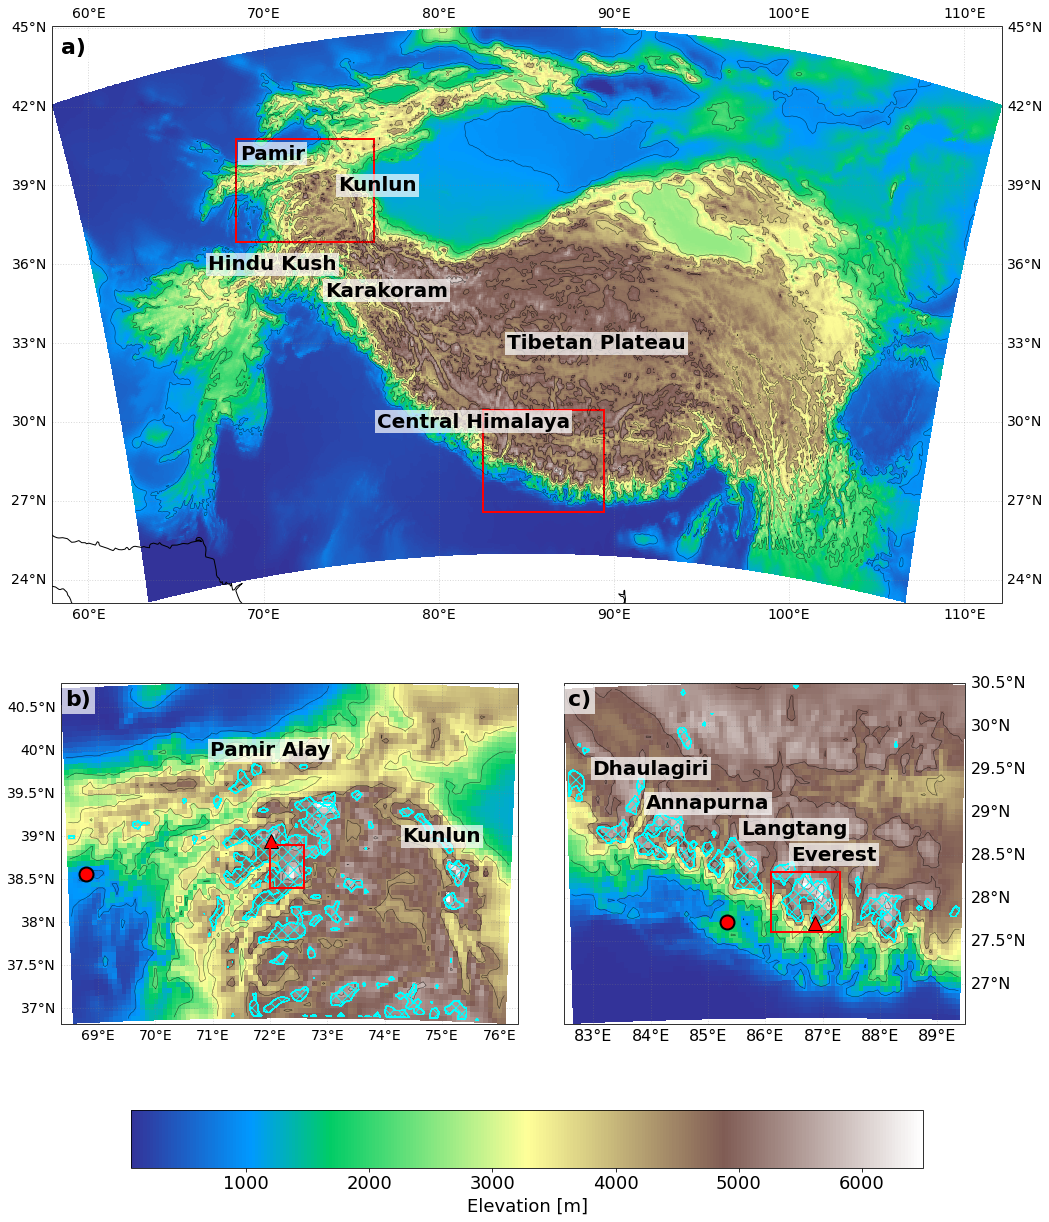

In [11]:
from matplotlib.patches import Rectangle

cmap='terrain'
# Compute rectangle coordinates automatically
nepal_box = [LONS_nepal.min().item(), LONS_nepal.max().item(),
             LATS_nepal.min().item(), LATS_nepal.max().item()]

pamir_box = [LONS_pamir.min().item(), LONS_pamir.max().item(),
             LATS_pamir.min().item(), LATS_pamir.max().item()]

glacioclim_box = [86.1, 87.3, 27.6, 28.3]
recap_box=[72,72.6,38.4,38.9]

# Create figure and gridspec layout
fig = plt.figure(figsize=(22, 40))
gs = fig.add_gridspec(2, 2, height_ratios=[1.75, 1])

# Row 1: full-width HMA plot
ax0 = fig.add_subplot(gs[0, :], projection=ccrs.PlateCarree())
CS0 = ax0.pcolormesh(LONS_hma, LATS_hma,dsSH_hma,
                   transform=ccrs.PlateCarree(),
                   cmap=cmap ,shading="auto")
ax0.coastlines()
#ax0.set_title('HMA Elevation')
gl = ax0.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                          linewidth=1, color="gray", alpha=0.3, linestyle=":")
gl.xlabel_style = {"size": 14}
gl.ylabel_style = {"size": 14}
ax0.set_aspect(1.5)
SH0 = ax0.contour(LONS_hma, LATS_hma, dsSH_hma,
                             levels=[1000,2000,3000,4000,5000,6000,7000],
                             colors="k", linewidths=0.5, alpha=0.7,
                             transform=ccrs.PlateCarree())
#ax0.clabel(SH0, inline=True, fontsize=12, fmt="%d")

# Add red rectangles for subdomains
for box in [nepal_box, pamir_box]:
    rect = Rectangle((box[0], box[2]), box[1]-box[0], box[3]-box[2],
                     linewidth=2, edgecolor='red', facecolor='none', transform=ccrs.PlateCarree())
    ax0.add_patch(rect)

# Row 2: two half-width subdomain plots
ax1 = fig.add_subplot(gs[1, 0], projection=ccrs.PlateCarree())
CS1 = ax1.pcolormesh(LONS_pamir, LATS_pamir,dsSH_pamir,
                   transform=ccrs.PlateCarree(),
                   cmap=cmap ,shading="auto")

#ax1.set_title('Pamir')
gl = ax1.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                          linewidth=1, color="gray", alpha=0.3, linestyle=":")
gl.xlabel_style = {"size": 14}
gl.ylabel_style = {"size": 14}
gl.top_labels = False
gl.right_labels = False
ax1.set_aspect(1.5)
SH1 = ax1.contour(LONS_pamir, LATS_pamir, dsSH_pamir,
                             levels=[1000,2000,3000,4000,5000,6000,7000],
                             colors="k", linewidths=0.5, alpha=0.7,
                             transform=ccrs.PlateCarree())

ICE1 = ax1.contourf(
    LONS_pamir, LATS_pamir, dsICE_pamir,
    levels=[20,100],
    hatches=['XX','XX', 'XX'],     # or ['X','X']
    colors='none',            # no face fill
    transform=ccrs.PlateCarree(),
    zorder=5                  # put hatch on top of pcolormesh
)

# --- Reliable way to force red hatches ---
for coll in ICE1.collections:
    coll.set_edgecolor('cyan')   # hatch color
    coll.set_linewidth(0.6)     # must be >0 for some backends to draw hatch
    coll.set_facecolor('none')  # ensure no fill hides hatch
    # ensure collection stays above main image
    coll.set_zorder(6)
# Add rectangle to ax1
rect = Rectangle(
    (recap_box[0], recap_box[2]),  # lower-left corner (lon, lat)
    recap_box[1] - recap_box[0],  # width (lon)
    recap_box[3] - recap_box[2],  # height (lat)
    linewidth=2,
    edgecolor='red',  # choose a color different from other boxes if you like
    facecolor='none',
    transform=ccrs.PlateCarree(),zorder=7
)
ax1.add_patch(rect)


ax2 = fig.add_subplot(gs[1, 1], projection=ccrs.PlateCarree())
CS2 = ax2.pcolormesh(LONS_nepal, LATS_nepal,dsSH_nepal,
                   transform=ccrs.PlateCarree(),
                   cmap=cmap ,shading="auto")

#ax2.set_title('Nepal')
gl = ax2.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                          linewidth=1, color="gray", alpha=0.3, linestyle=":")
gl.xlabel_style = {"size": 16}
gl.ylabel_style = {"size": 16}
gl.top_labels = False
gl.left_labels = False
ax2.set_aspect(1.5)
SH2 = ax2.contour(LONS_nepal, LATS_nepal, dsSH_nepal,
                             levels=[1000,2000,3000,4000,5000,6000,7000],
                             colors="k", linewidths=0.5, alpha=0.7,
                             transform=ccrs.PlateCarree())

ICE2 = ax2.contourf(
    LONS_nepal, LATS_nepal, dsICE_nepal,
    levels=[20, 100],
    hatches=['XX', 'XX'],     # or ['X','X']
    colors='none',            # no face fill
    transform=ccrs.PlateCarree(),
    zorder=4                  # put hatch on top of pcolormesh
)

# --- Reliable way to force red hatches ---
for coll in ICE2.collections:
    coll.set_edgecolor('cyan')   # hatch color
    coll.set_linewidth(0.6)     # must be >0 for some backends to draw hatch
    coll.set_facecolor('none')  # ensure no fill hides hatch
    # ensure collection stays above main image
    coll.set_zorder(6)
# Add rectangle to ax1
rect = Rectangle(
    (glacioclim_box[0], glacioclim_box[2]),  # lower-left corner (lon, lat)
    glacioclim_box[1] - glacioclim_box[0],  # width (lon)
    glacioclim_box[3] - glacioclim_box[2],  # height (lat)
    linewidth=2,
    edgecolor='red',  # choose a color different from other boxes if you like
    facecolor='none',
    transform=ccrs.PlateCarree(),zorder=7
)
ax2.add_patch(rect)

for r in regions:
    ax0.text(
        r["lon"], r["lat"], r["name"],
        horizontalalignment='center',
        verticalalignment='center',
        fontsize=20,
        fontweight='bold',
        color='black',
        transform=ccrs.PlateCarree(),
        zorder=6,
        bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=2)
    )    
# Plot peaks (triangle)
for p in ax1_peaks:
    ax1.plot(p["lon"], p["lat"], '^', color='red',markeredgecolor='black', markersize=14,
             transform=ccrs.PlateCarree(), zorder=6)

# Plot cities (double circle)
for c in ax1_cities:
    ax1.plot(c["lon"], c["lat"], 'o', markersize=14, markeredgewidth=2,
             markerfacecolor='red', markeredgecolor='black',
             transform=ccrs.PlateCarree(), zorder=9)

# Optionally add labels
#for p in ax1_peaks:
#    ax1.text(p["lon"], p["lat"], p["name"], fontsize=14, fontweight='bold',
#             horizontalalignment='left', verticalalignment='bottom',zorder=9,
#             transform=ccrs.PlateCarree(), bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=2))

#for c in ax1_cities:
#    ax1.text(c["lon"], c["lat"], c["name"], fontsize=14, fontweight='bold',
#             horizontalalignment='left', verticalalignment='bottom',zorder=9,
#             transform=ccrs.PlateCarree(), bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=2))
for r in regions_pamir:
    ax1.text(
        r["lon"], r["lat"], r["name"],
        horizontalalignment='center',
        verticalalignment='center',
        fontsize=20,
        fontweight='bold',
        color='black',
        transform=ccrs.PlateCarree(),
        zorder=6,
        bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=2)
    )    

# --- ax2 ---
# Plot peaks (triangle)
for p in ax2_peaks:
    ax2.plot(p["lon"], p["lat"], '^', color='red', markeredgecolor='black',markersize=14,
             transform=ccrs.PlateCarree(), zorder=9)

# Plot cities (double circle)
for c in ax2_cities:
    ax2.plot(c["lon"], c["lat"], 'o', markersize=14, markeredgewidth=2,
             markerfacecolor='red', markeredgecolor='black',
             transform=ccrs.PlateCarree(), zorder=9)

# Add labels
#for p in ax2_peaks:
#    ax2.text(p["lon"], p["lat"], p["name"], fontsize=14, fontweight='bold',
#             horizontalalignment='left', verticalalignment='bottom',zorder=9,
#             transform=ccrs.PlateCarree(), bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=2))

#for c in ax2_cities:
#    ax2.text(c["lon"]-2, c["lat"], c["name"], fontsize=14, fontweight='bold',
#             horizontalalignment='left', verticalalignment='bottom',zorder=9,
#             transform=ccrs.PlateCarree(), bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=2))

for r in regions_nepal:
    ax2.text(
        r["lon"], r["lat"], r["name"],
        horizontalalignment='center',
        verticalalignment='center',
        fontsize=20,
        fontweight='bold',
        color='black',
        transform=ccrs.PlateCarree(),
        zorder=6,
        bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=2)
    )    


    
cbar_ax = fig.add_axes([0.25, 0.15, 0.5, 0.02])  # [left, bottom, width, height]
cbar = fig.colorbar(CS2, cax=cbar_ax, orientation="horizontal")
cbar.set_label(f"{'Elevation '}[{'m'}]", fontsize=18)
cbar.ax.tick_params(labelsize=18)

# Panel labels
ax0.text(0.01, 0.98, 'a)', transform=ax0.transAxes,
         fontsize=22, fontweight='bold',
         va='top', ha='left',
         bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

ax1.text(0.01, 0.98, 'b)', transform=ax1.transAxes,
         fontsize=22, fontweight='bold',
         va='top', ha='left',
         bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

ax2.text(0.01, 0.98, 'c)', transform=ax2.transAxes,
         fontsize=22, fontweight='bold',
         va='top', ha='left',
         bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))


fig.subplots_adjust(left=0.2, right=0.8, top=0.55, bottom=0.2, wspace=0.00000001, hspace=0.15)
#plt.tight_layout()
#plt.suptitle(f'Annual mean ({iyr}-{fyr})',fontsize=18,y=0.87)

plotname=f'FIG1_map_MAR.HMA_nepal_pamir_rev1'
#plotsDir="/home/santolam/MyPythonLibrary/MAR_HMA_evaluation_paper/scripts_paper_on_evaluation_MAR/figures_paper_on_evaluation/"

#plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight")
#plt.savefig(plotsDir + plotname + '.eps', format='eps', dpi=300)
#print(f"Saved: {plotsDir}{plotname}.png")

plt.show()

